# Dat200 CA5

## Group 3 Members

- Vincius Millan
- Stig Espen Paulsberg
- Zaur Kambiev

Kaggle team `Group 3`

# Imports

In [114]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Reading data

In [115]:
df = pd.read_csv("dat-200-ca-5-h-2026/train.csv", index_col="id")

# Data exploration

Look at data information

In [116]:
df.info()

<class 'pandas.DataFrame'>
Index: 367500 entries, 193355 to 186708
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           345653 non-null  float64
 1   sleep_duration_hrs            340323 non-null  float64
 2   sleep_quality_score           357702 non-null  float64
 3   cardio_mins_wk                355386 non-null  float64
 4   water_intake_liters           358969 non-null  float64
 5   screen_time_recreational_hrs  338865 non-null  float64
 6   social_media_hrs              362207 non-null  float64
 7   blood_pressure_sys            357789 non-null  float64
 8   diet_ultra_processed_pct      354171 non-null  float64
 9   diet_omega3_freq              344987 non-null  float64
 10  smoking_status                342146 non-null  str    
 11  alcohol_drinks_wk             346938 non-null  float64
 12  novel_learning_hrs_wk         340773 non-null  float64


Look at first few lines of the dataset

In [117]:
df.head()

,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
id,,,,,,,,,,,,,,,,
193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


Check missing and duplicated values.

In [118]:
print(f"Missing values per feature: {df.isna().sum()}\n")
print(f"Missing values total: {df.isna().sum().sum()}\n")
print(f"Duplicated rows: {df.duplicated().sum()}")

Missing values per feature: age                             21847
sleep_duration_hrs              27177
sleep_quality_score              9798
cardio_mins_wk                  12114
water_intake_liters              8531
screen_time_recreational_hrs    28635
social_media_hrs                 5293
blood_pressure_sys               9711
diet_ultra_processed_pct        13329
diet_omega3_freq                22513
smoking_status                  25354
alcohol_drinks_wk               20562
novel_learning_hrs_wk           26727
social_connection_score         24873
chronic_stress_score            17929
target                              0
dtype: int64

Missing values total: 274393

Duplicated rows: 17500


### Summary

The dataset is large, and there are many missing values and duplicated rows.

1. Age (`age`):
    - Between 18 and 90.

2. Systolic blood pressure (`blood_pressure_sys`) read more about it here:
    - https://www.nhlbi.nih.gov/health/high-blood-pressure

3. Hourse of sleep per night (`sleep_duration_hrs`):
    - Average hours of sleep per night. Can't be negative, and must look into high values.

4. Sleep quality score (`sleep_quality_score`):
    - *Self-rated* scale from 1 (poor) to 10 (excellent).

5. Minutes of cardio exercise per week (`cardio_mins_wk`):
    - Total minutes of elevated heart rate exercise. Log-normal dist.

6. Water intake in liters (`water_intake_liters`):
    - Average daily water intake. Added as a noise variable..

7. Screen time on free time (`screen_time_recreational_hrs`):
    - Daily hours spent on screens not related to work.

8. Social media hours (`social_media_hrs`):
    - Daily hours spent on specifically social media apps.

9. Ultraprocessed foods diet percentage (`diet_ultra_processed_pct`):
    - Estimated % of diet containing highly processed foods.

10. Omega3 frequency (`diet_omega3_freq`):
    - Days per week of consuming foods like fish, nuts and seeds (brain-healthy).

11. Smoking status (`smoking_statu`):
    - "Current", "Former", "Never"

12. Consumption of alcoholic beverages (`alcohol_drinks_wk`):
    - Total consumption of alcoholic beverages per week.

13. Novel learning hourse per week (`novel_learning_hrs_wk`):
    -  Hours spent per week learning a new difficult task. A language, instrument for example.

14. Social connection score (`social_connection_score`):
    - *Self-rated* scale from 1 (isolated) to 10 (highly supported).

15. Chronic stress score (`chronic_stress_score`):
    - *Self-rated* scale from 1 (low) to 10 (high) on perceived daily stress. 

16. Target (`target`):
    - Cognitive assessment score. A baseline score minues penalties (age, stress, poor diet, smoking) plus bonuses (cardio, learning, social connection).

# Data visualization

Create pairplot

In [119]:
# sns.pairplot(df)

Histograms

In [120]:
# n_features = len(df.columns)
# n_cols = 2
# n_rows = (n_features + n_cols - 1) // n_cols

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))
# axes = axes.flatten()

# for i, feature in enumerate(df.columns):
#     sns.histplot(
#         data=df,
#         x=feature,
#         ax=axes[i],
#         bins=50
#     )
#     axes[i].set_title(feature)

# plt.tight_layout()
# plt.show()
# plt.close()
    

### Boxplots

In [121]:
# n_features = len(df.columns)
# n_cols = 2
# n_rows = (n_features + n_cols - 1) // n_cols

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))
# axes = axes.flatten()

# for i, feature in enumerate(df.columns):
#     sns.boxplot(
#         data=df,
#         y=feature,
#         ax=axes[i]
#     )
#     axes[i].set_title(feature)

# plt.tight_layout()
# plt.show()
# plt.close()

### Summary

There are a lot of negative values that doesn't make sense for many different features. Some serious cleaning needs to be done before I can make any sense of the pairplot. 

- Histograms
There are many values that are outside of the range of the description of the features. Need to filter on many of the features. Negative values for example. and scores over the maximum score.

- Boxplots
There are some clear cutoff values here that needs to be dealt with. Only thing that was ambiguous to me was `social_media_hrs`. I will set the cutoff point the same as `screen_time_recreational_hrs`.

# Data cleaning

Remove duplicated values

In [122]:
df = df.drop_duplicates()
df.info()

<class 'pandas.DataFrame'>
Index: 350000 entries, 193355 to 186708
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           329197 non-null  float64
 1   sleep_duration_hrs            324108 non-null  float64
 2   sleep_quality_score           340685 non-null  float64
 3   cardio_mins_wk                338447 non-null  float64
 4   water_intake_liters           341900 non-null  float64
 5   screen_time_recreational_hrs  322694 non-null  float64
 6   social_media_hrs              344953 non-null  float64
 7   blood_pressure_sys            340790 non-null  float64
 8   diet_ultra_processed_pct      337333 non-null  float64
 9   diet_omega3_freq              328543 non-null  float64
 10  smoking_status                325888 non-null  str    
 11  alcohol_drinks_wk             330400 non-null  float64
 12  novel_learning_hrs_wk         324581 non-null  float64


Remove null values. The dataset is large enough to drop missing values instead of doing imputations.

In [123]:
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 162172 entries, 242385 to 186708
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           162172 non-null  float64
 1   sleep_duration_hrs            162172 non-null  float64
 2   sleep_quality_score           162172 non-null  float64
 3   cardio_mins_wk                162172 non-null  float64
 4   water_intake_liters           162172 non-null  float64
 5   screen_time_recreational_hrs  162172 non-null  float64
 6   social_media_hrs              162172 non-null  float64
 7   blood_pressure_sys            162172 non-null  float64
 8   diet_ultra_processed_pct      162172 non-null  float64
 9   diet_omega3_freq              162172 non-null  float64
 10  smoking_status                162172 non-null  str    
 11  alcohol_drinks_wk             162172 non-null  float64
 12  novel_learning_hrs_wk         162172 non-null  float64


Remove invalid values like negative values and scores lower/higher than min/max thresholds

Create dictionairy for filtering

In [124]:
bounds = {
    'age': (18, 90),                            # Age between 18 and 90 according to assignment
    'sleep_duration_hrs': (2, 12),              # Can't sleep negative. Set upper limit at 12 hrs
    'sleep_quality_score': (1, 10),             # Self-rated 1-10
    'cardio_mins_wk': (0, 600),                 # Can't be negative. Cutoff at 600.
    'water_intake_liters': (0, 5),              # Can't be negative. Cutoff at 5 liters.
    'screen_time_recreational_hrs': (0, 17),    # Can't be negative. Cutoff at 17 hours.
    'social_media_hrs': (0, 17),                # Same as screen time
    'blood_pressure_sys': (80, 180),            # Reasonable BP range (mmHg)
    'diet_ultra_processed_pct': (0, 100),       # Percentage
    'diet_omega3_freq': (0, 7),                 # Days per week
    'alcohol_drinks_wk': (0, None),             # Can't be negative
    'novel_learning_hrs_wk': (0, None),         # Can't be negative
    'social_connection_score': (1, 10),         # Self-rated 1-10
    'chronic_stress_score': (1, 10),            # Self-rated 1-10
    'target': (0, None)                         # Keep all target values
}

Appllying lower and upper bounds to the dataset. Removing entire rows if any column has an invalid value. 

In [125]:
print(len(df))

conditions = []
for feature, (lower, upper) in bounds.items():
    if upper is None:
        conditions.append(df[feature] >= lower)
    else:
        conditions.append((df[feature] >= lower) & (df[feature] <= upper))

df = df[pd.concat(conditions, axis=1).all(axis=1)]

print(len(df))

162172
152026


One hot encoding

In [126]:
df = pd.get_dummies(df, columns = ['smoking_status'], drop_first=True)
df.info()

<class 'pandas.DataFrame'>
Index: 152026 entries, 242385 to 186708
Data columns (total 17 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           152026 non-null  float64
 1   sleep_duration_hrs            152026 non-null  float64
 2   sleep_quality_score           152026 non-null  float64
 3   cardio_mins_wk                152026 non-null  float64
 4   water_intake_liters           152026 non-null  float64
 5   screen_time_recreational_hrs  152026 non-null  float64
 6   social_media_hrs              152026 non-null  float64
 7   blood_pressure_sys            152026 non-null  float64
 8   diet_ultra_processed_pct      152026 non-null  float64
 9   diet_omega3_freq              152026 non-null  float64
 10  alcohol_drinks_wk             152026 non-null  float64
 11  novel_learning_hrs_wk         152026 non-null  float64
 12  social_connection_score       152026 non-null  float64


# Data exploration and visualisation

<Axes: >

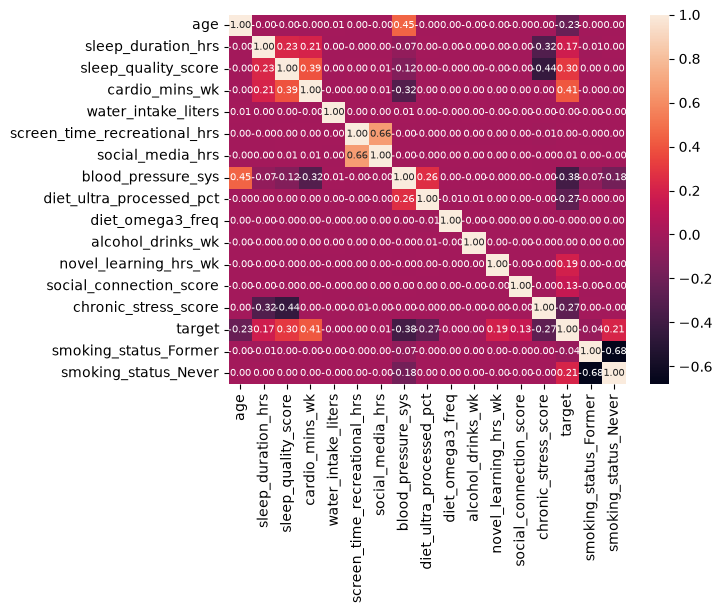

In [127]:
sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    annot_kws={'size': 7}
)

### Summary 

`social_media_hrs` and `screen_time_recreational_hrs` are highly correlated, which makes sense.

### Histograms and boxplots

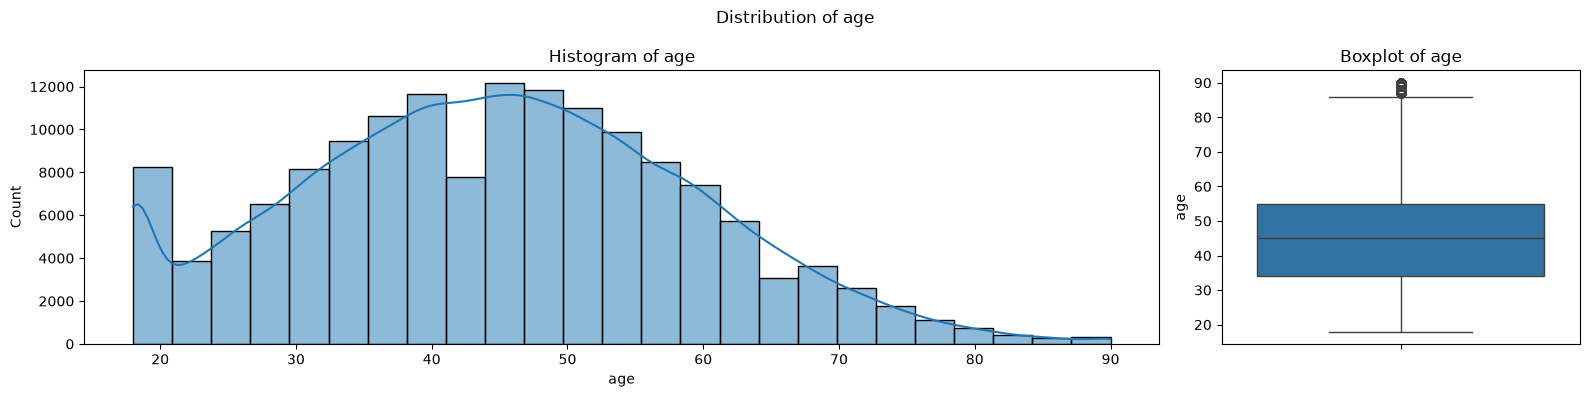

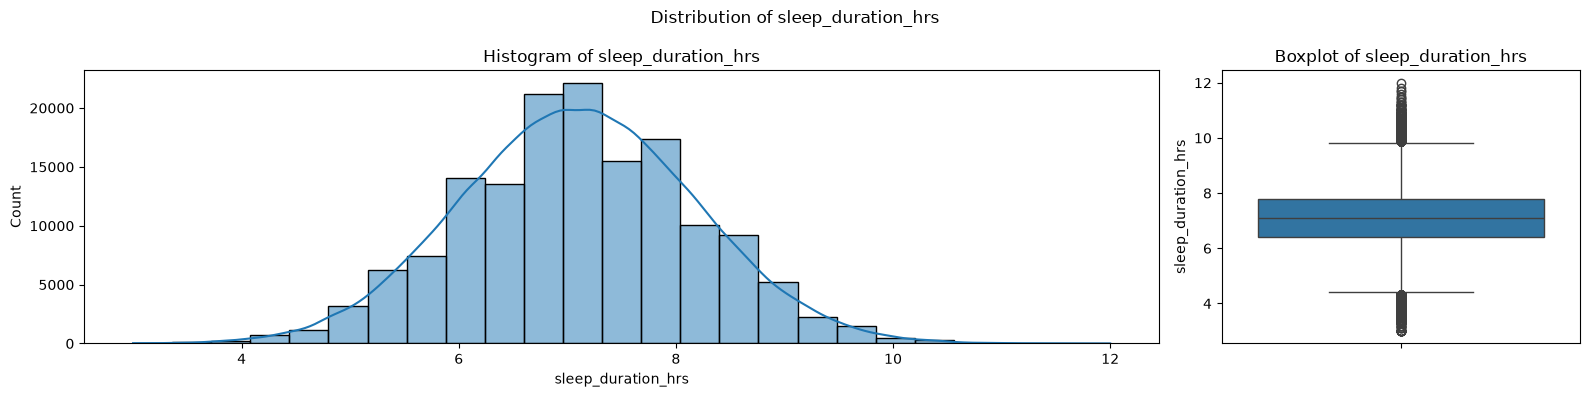

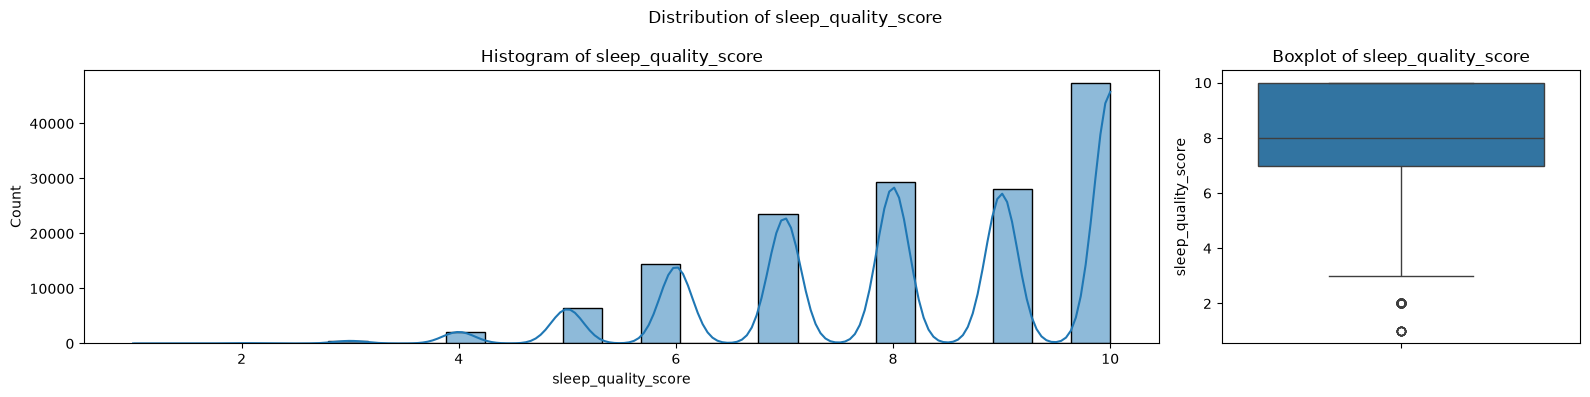

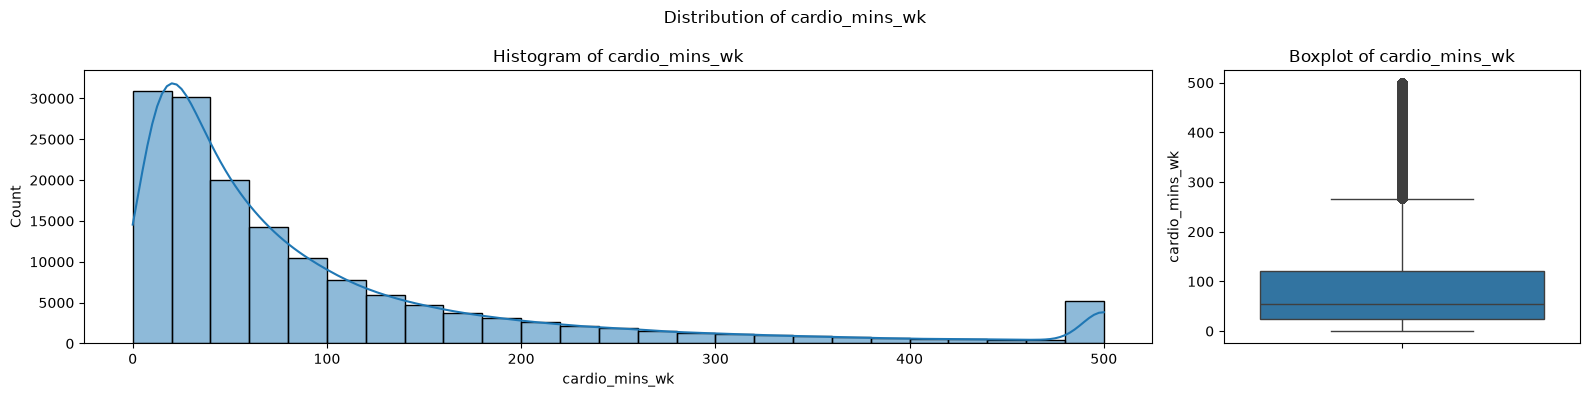

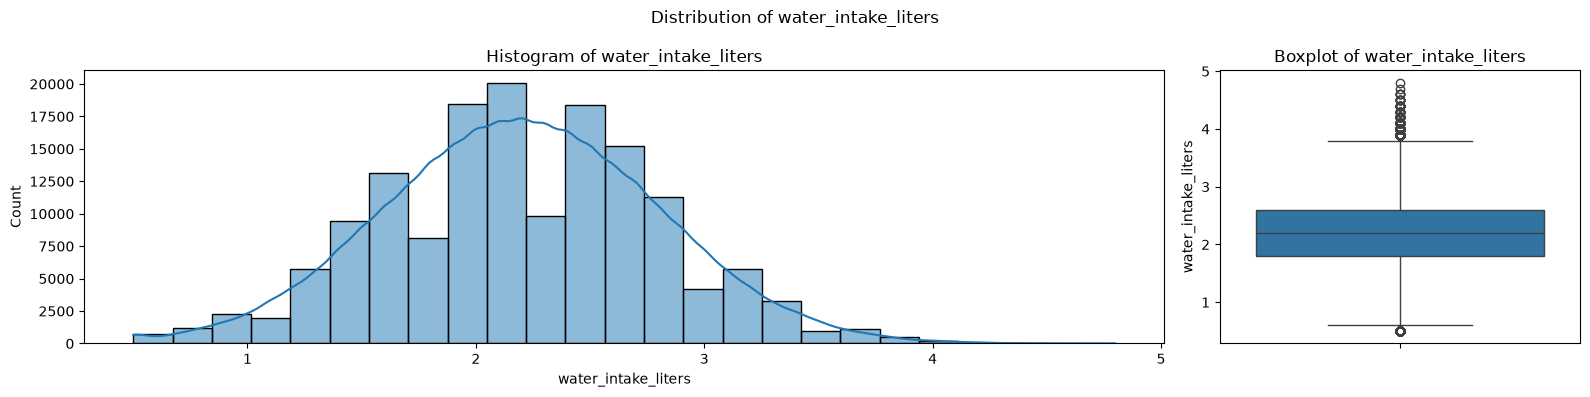

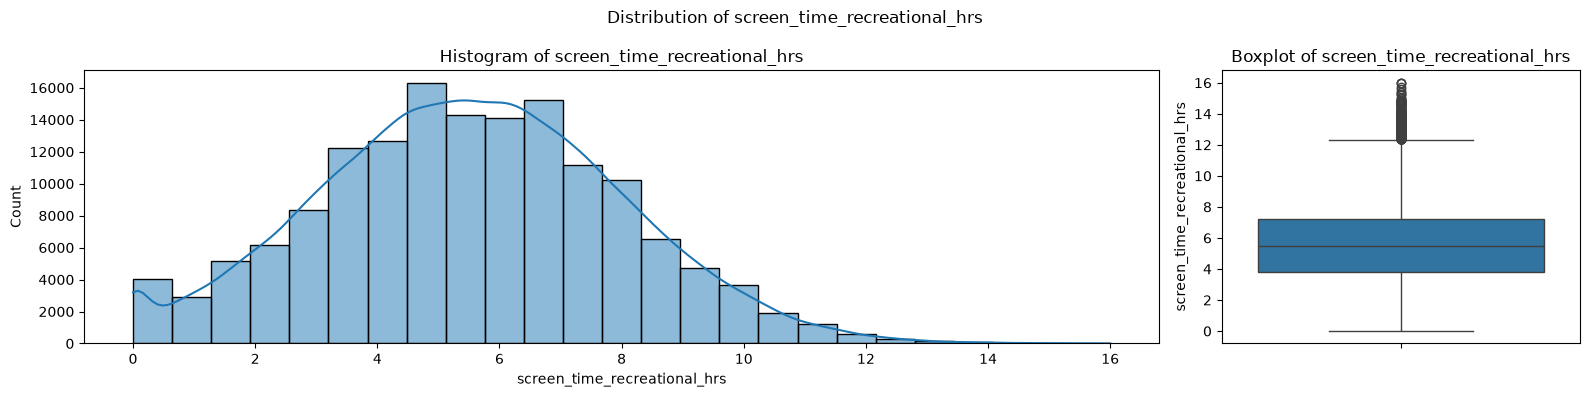

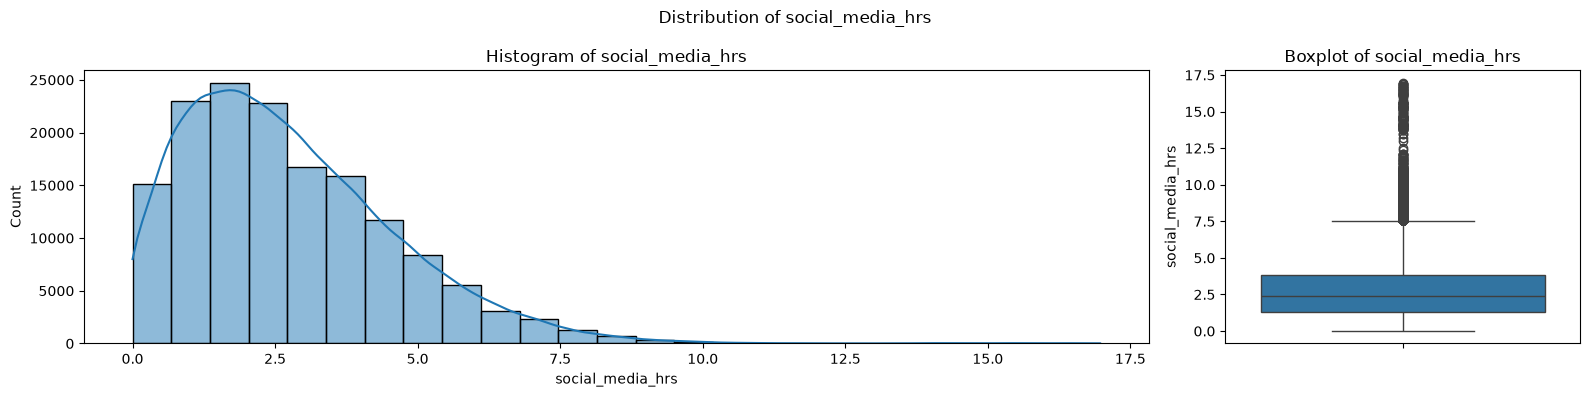

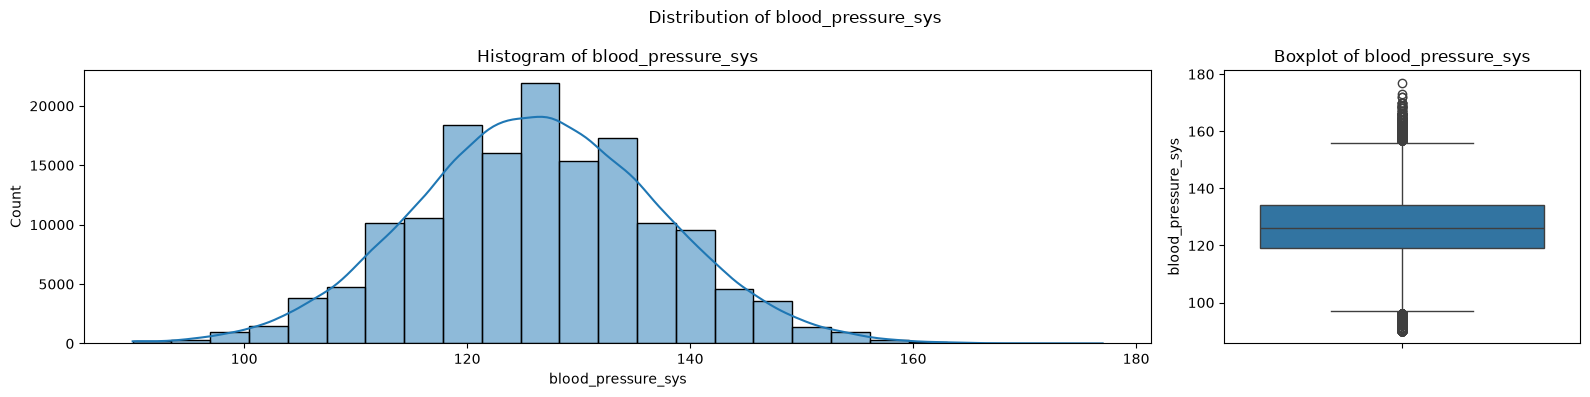

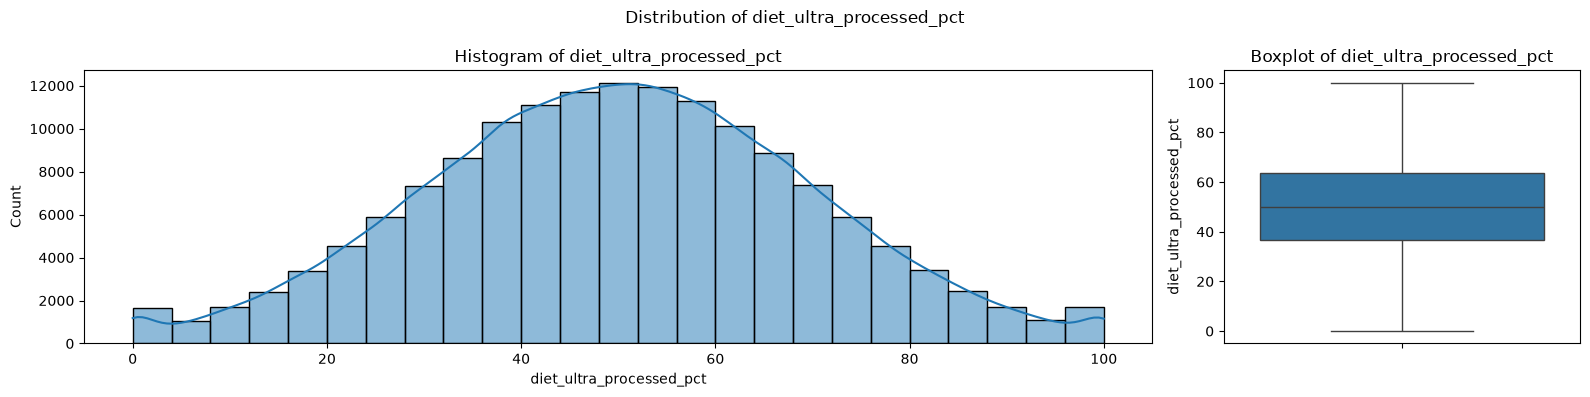

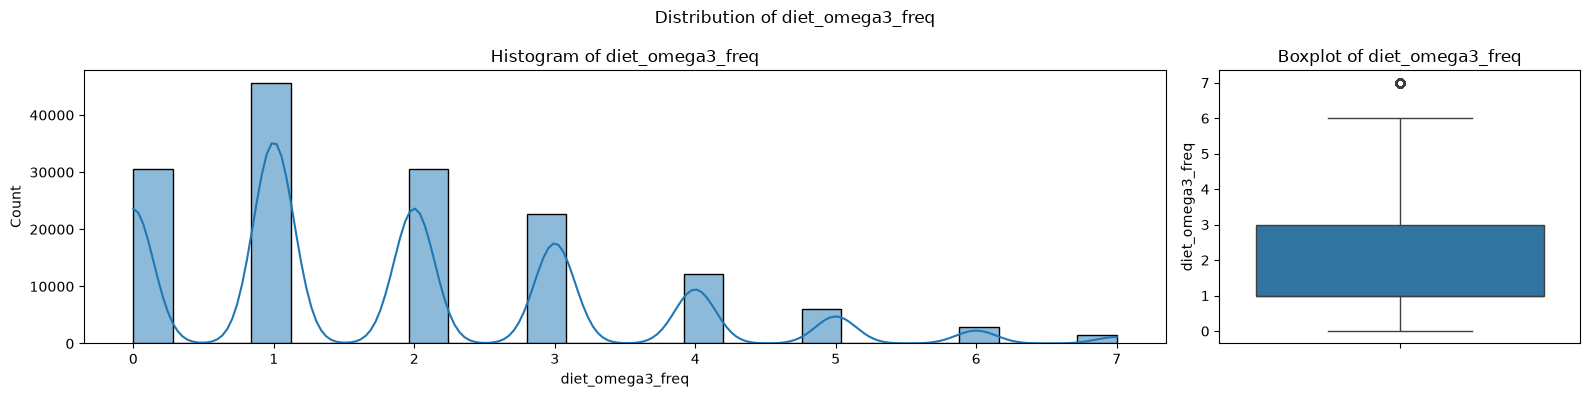

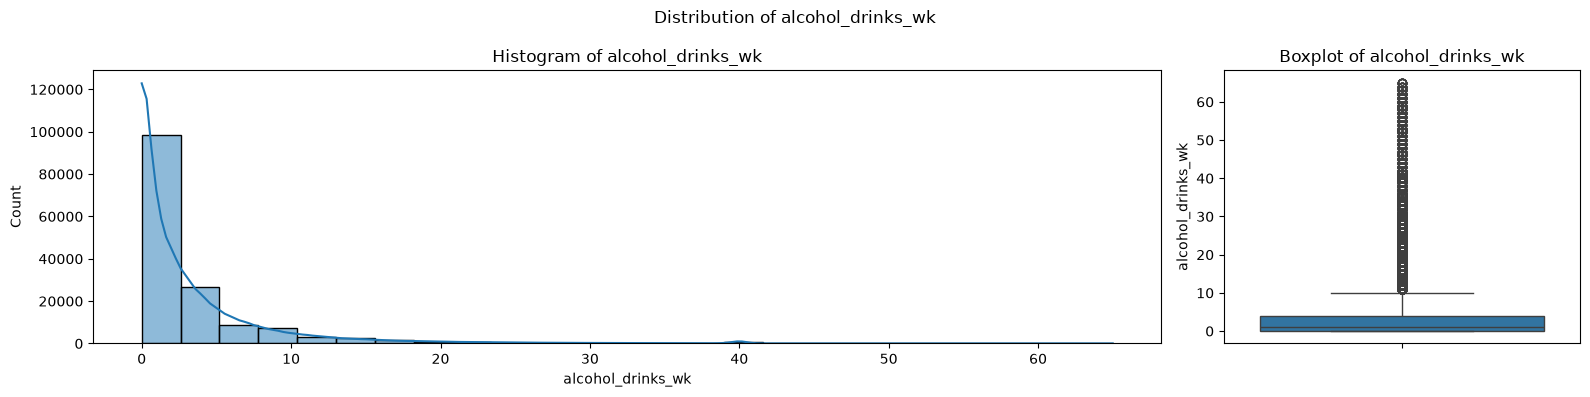

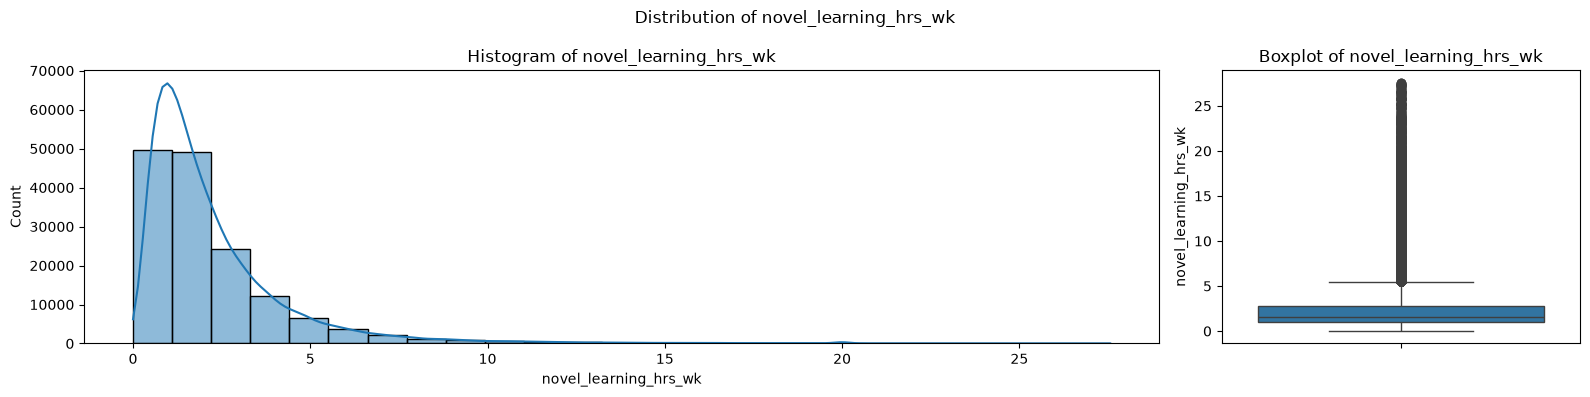

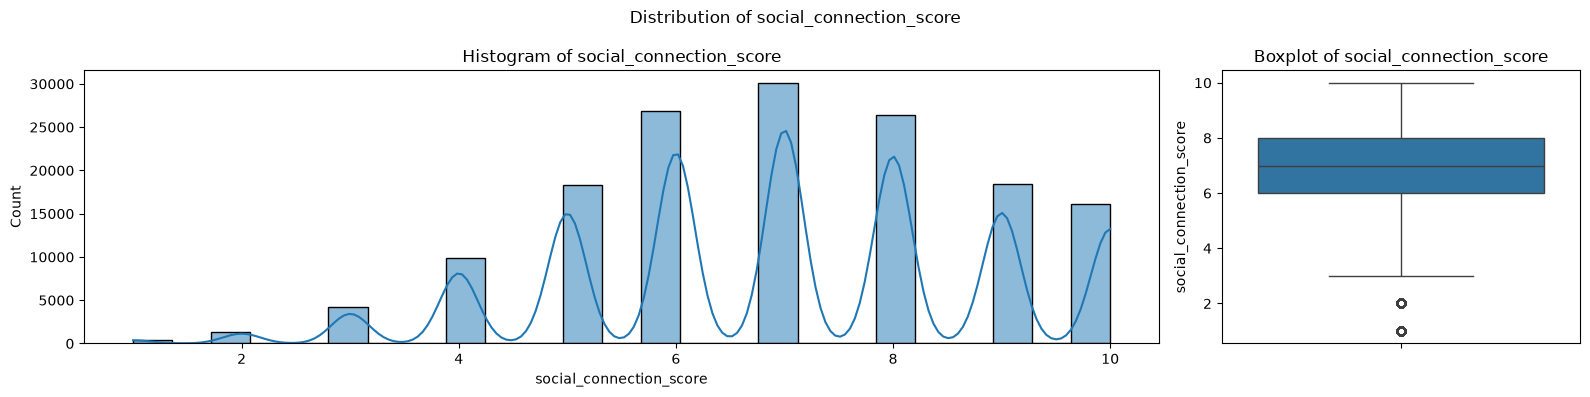

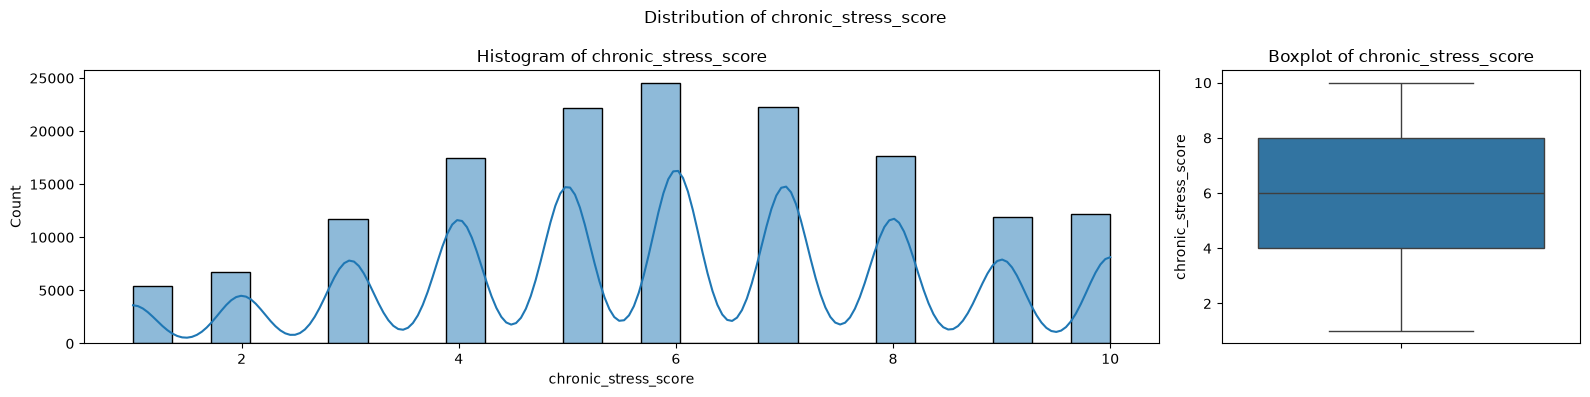

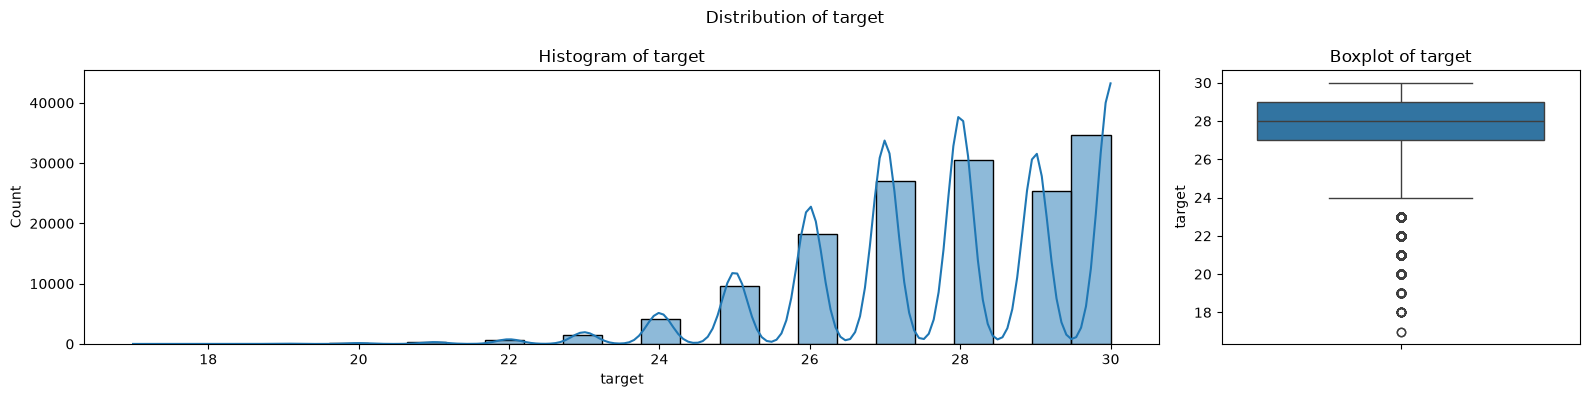

In [129]:
for feature in df.columns:
    if df[feature].dtype == 'bool': # skips boolean datatypes
        continue


    fig, axes = plt.subplots(
        1, 2, 
        figsize=(16, 4), 
        gridspec_kw={'width_ratios': [3, 1]} # ratio of graphs
    )

    # Histogram
    sns.histplot(
        data=df,
        x=feature,
        ax=axes[0], 
        kde=True,  # add a smooth line
        bins=25
    )
    axes[0].set_title(f'Histogram of {feature}')

    # Boxplot
    sns.boxplot(
        data=df,
        y=feature,
        ax=axes[1]
    )
    axes[1].set_title(f'Boxplot of {feature}')

    fig.suptitle(f'Distribution of {feature}')
    fig.tight_layout()
    plt.show()
    plt.close()

# Pipeline A

# Pipeline B

# Pipeline C

# Model comparison and evaluation

# Kaggle submission